# Pipelining: chaining a PCA and a classifier, tuned by grid search (scikit-learn vs Moxie)

**Reference example:** `../scikit-learn/examples/compose/plot_digits_pipe.py` at scikit-learn
`4358542a1bd39af2e7e1cbace8b9fed067473c5b`
([gallery page](https://scikit-learn.org/dev/auto_examples/compose/plot_digits_pipe.html)).

**Scenario:** `Pipeline([("scaler", StandardScaler()), ("pca", PCA()), ("logistic", LogisticRegression(max_iter=10000, tol=0.1))])`
on the bundled digits data (1797 × 64, no download), tuned with `GridSearchCV` over
`pca__n_components ∈ {5, 15, 30, 45, 60}` × `C ∈ logspace(-4, 4, 4)` with the default 5-fold
`StratifiedKFold`, then `PCA().fit(X_digits).explained_variance_ratio_` for the scree plot.
This is a cross-family composition: preprocessing → decomposition → classifier → model_selection.

**Adaptations (each recorded as GAP/ADAPTED below):**

1. `LogisticRegression` does not exist in Moxie (linear_model #8). Both sides use `SVC()` (RBF, the
   defaults) as the final step instead, with the same `C` grid. The official example still runs
   unchanged in section 1 for reference.
2. Moxie's `Pipeline` has two typed steps, so the three-step pipeline is
   `Pipeline(StandardScaler(), Pipeline(PCA(), SVC()))` (documented in `docs/pipeline/sequential.md`).
   Parameters are set through the typed nested `PipelineParams` record instead of `pca__n_components`.
3. `GridSearchCV` (and `cross_val_score`) over a `Pipeline` crashes the Mojo 1.0 compiler
   (model_selection #3 part 1; `--expect-fail` cell below). The search is therefore written as
   sklearn's own loop: `clone` the pipeline per candidate and fold, `set_params`, `fit` on the train
   rows, `score` on the test rows, rank, refit the best candidate on all rows. A one-line shared
   contract fix is proposed as the patch `cross_family-pipeline-search.patch`.
4. `n_jobs=2` is dropped (Moxie is serial; results are unaffected). The polars result table is
   replaced by the equivalent NumPy grouping (polars is not in the notebook environment).

**Determinism:** deterministic. Unshuffled stratified folds, LIBSVM without probability, full SVD PCA
(`svd_solver="auto"` picks `covariance_eigh` here for both). Predictions and fold accuracies are
compared exactly; continuous PCA quantities with a stated tolerance.

In [1]:
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "notebooks/_support/moxie_nb.py").exists())
sys.path.insert(0, str(ROOT / "notebooks/_support"))
%load_ext moxie_nb
nb = moxie_nb.Session("cross_family/plot_digits_pipe")

## 1. scikit-learn: the official example (LogisticRegression), unchanged except `n_jobs` and polars

In [2]:
import matplotlib.pyplot as plt
import numpy as np

from sklearn import datasets
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

plt.rcParams["figure.dpi"] = 60

# Define a pipeline to search for the best combination of PCA truncation
# and classifier regularization.
pca = PCA()
# Define a Standard Scaler to normalize inputs
scaler = StandardScaler()

# set the tolerance to a large value to make the example faster
logistic = LogisticRegression(max_iter=10000, tol=0.1)
pipe = Pipeline(steps=[("scaler", scaler), ("pca", pca), ("logistic", logistic)])

X_digits, y_digits = datasets.load_digits(return_X_y=True)
# Parameters of pipelines can be set using '__' separated parameter names:
param_grid = {
    "pca__n_components": [5, 15, 30, 45, 60],
    "logistic__C": np.logspace(-4, 4, 4),
}
search = GridSearchCV(pipe, param_grid)
search.fit(X_digits, y_digits)
print("Best parameter (CV score=%0.3f):" % search.best_score_)
print(search.best_params_)

Best parameter (CV score=0.874):
{'logistic__C': np.float64(21.54434690031882), 'pca__n_components': 60}


## 2. scikit-learn: the adapted scenario that Moxie runs (`SVC()` as the final step)

In [3]:
from sklearn.svm import SVC

sk_pipe = Pipeline(steps=[("scaler", StandardScaler()), ("pca", PCA()), ("svc", SVC())])
sk_grid = {"pca__n_components": [5, 15, 30, 45, 60], "svc__C": np.logspace(-4, 4, 4)}
sk_search = GridSearchCV(sk_pipe, sk_grid).fit(X_digits, y_digits)
res = sk_search.cv_results_
# ParameterGrid order: sorted keys, last key fastest -> pca__n_components outer, svc__C inner.
print([(p["pca__n_components"], round(p["svc__C"], 4)) for p in res["params"][:5]])
print("Best parameter (CV score=%0.3f):" % sk_search.best_score_, sk_search.best_params_)
sk_split = np.stack([res[f"split{k}_test_score"] for k in range(5)], axis=1)
sk_full_pca = PCA().fit(X_digits)
nb.share(X=X_digits, y=y_digits.astype(np.int64), C=np.logspace(-4, 4, 4))

[(5, np.float64(0.0001)), (5, np.float64(0.0464)), (5, np.float64(21.5443)), (5, np.float64(10000.0)), (15, np.float64(0.0001))]
Best parameter (CV score=0.953): {'pca__n_components': 45, 'svc__C': np.float64(21.54434690031882)}


## 3. Moxie (native Mojo)

The search is sklearn's `GridSearchCV` loop written out (adaptation 3): for each candidate in
`ParameterGrid` order and each `StratifiedKFold(5)` split, clone the unfitted nested pipeline,
apply the candidate through typed `set_params`, fit on the train rows and score (accuracy) on the
test rows. The best candidate (lowest index among ties, like `rank_test_score`/`best_index_`) is
refitted on all rows.

In [4]:
%%mojo digits_pipe
from moxie.base import clone
from moxie.decomposition import PCA
from moxie.model_selection import IndexArray, IndexSplit, StratifiedKFold
from moxie.pipeline import Pipeline
from moxie.preprocessing import StandardScaler
from moxie.svm import SVC
from moxie_nb_io import load, load_ints, save, save_floats, save_ints
from numojo import NDArray, Shape, Item

comptime Dense = NDArray[DType.float64]
comptime Labels = List[Int]
comptime Reduce = Pipeline[PCA[], SVC[Int]]
comptime Pipe = Pipeline[StandardScaler[], Reduce]


def take_rows(X: Dense, rows: IndexArray) raises -> Dense:
    var out = Dense(Shape(rows.size, X.shape[1]))
    for i in range(rows.size):
        for j in range(X.shape[1]):
            out[Item(i, j)] = X[Item(Int(rows[Item(i)]), j)]
    return out^


def take_labels(y: Labels, rows: IndexArray) raises -> Labels:
    var out = Labels()
    for i in range(rows.size):
        out.append(y[Int(rows[Item(i)])])
    return out^


def stratified(y: Labels) raises -> List[IndexSplit]:
    var codes = IndexArray(Shape(len(y)))
    for i in range(len(y)):
        codes[Item(i)] = Int64(y[i])
    var cursor = StratifiedKFold(5).split(len(y), codes^)
    var out = List[IndexSplit]()
    while True:
        var pair = cursor.next()
        if not pair:
            break
        out.append(pair.value().copy())
    return out^


def main() raises:
    var X = load("X")
    var y = load_ints("y")
    var Cs = load("C")
    var template = Pipeline(
        StandardScaler(),
        Pipeline(PCA(), SVC[Int](), transformer_name="pca", estimator_name="svc"),
        transformer_name="scaler", estimator_name="reduce",
    )
    var components: List[Int] = [5, 15, 30, 45, 60]
    var splits = stratified(y)
    var split_scores = Dense(Shape(len(components) * Cs.size, len(splits)))
    var means = List[Float64]()
    var best = 0
    for a in range(len(components)):
        for b in range(Cs.size):
            var candidate = a * Cs.size + b
            var total = 0.0
            for k in range(len(splits)):
                # clone (unfitted), then pca__n_components / svc__C via the typed nested record.
                # Written inline: on Mojo 1.0 a Pipeline cannot cross a concrete function
                # signature (model_selection #3 part 1).
                var model = clone(template)
                var config = model.get_params()
                config.estimator.transformer.n_components = components[a]
                config.estimator.estimator.C = Cs.item(b)
                _ = model.set_params(config)
                _ = model.fit(take_rows(X, splits[k].train), take_labels(y, splits[k].train))
                var s = model.score(take_rows(X, splits[k].test), take_labels(y, splits[k].test))
                split_scores[Item(candidate, k)] = s
                total += s
            means.append(total / Float64(len(splits)))
            if means[candidate] > means[best]:
                best = candidate
    var best_model = clone(template)
    var best_config = best_model.get_params()
    best_config.estimator.transformer.n_components = components[best // Cs.size]
    best_config.estimator.estimator.C = Cs.item(best % Cs.size)
    _ = best_model.set_params(best_config)
    _ = best_model.fit(X, y)
    print("Best parameter (CV score=" + String(means[best]) + "): pca__n_components=",
          components[best // Cs.size], " svc__C=", Cs.item(best % Cs.size))
    save("split_scores", split_scores)
    save_floats("means", means)
    save_ints("best_index", [best])
    save_ints("best_predict", best_model.predict(X))
    print("refitted pipeline is fitted:", best_model.__sklearn_is_fitted__(),
          " n_features_in_:", best_model.n_features_in_())

    # Scree plot input: PCA on the raw digits, all components.
    var pca = PCA()
    _ = pca.fit(X)
    save("explained_variance_ratio", pca.explained_variance_ratio_.value())
    save_ints("n_components_", [pca.n_components_])

Best parameter (CV score=0.9526988548437016): pca__n_components= 45  svc__C= 21.54434690031882
refitted pipeline is fitted: True  n_features_in_: 64


## 4. Side by side and parity

In [5]:
mx = nb.results["digits_pipe"]
mx_means = np.asarray(mx["means"])
moxie_nb.side_by_side(
    sklearn=np.c_[res["mean_test_score"], res["rank_test_score"]][:8],
    moxie=np.c_[mx_means, len(mx_means) - np.argsort(np.argsort(mx_means, kind="stable"), kind="stable")][:8],
)
nb.compare("split test accuracies (20 candidates x 5 folds)", sk_split, mx["split_scores"], exact=True)
nb.compare("mean_test_score", res["mean_test_score"], mx_means, rtol=0, atol=1e-15,
           reason="mean of five identical fold accuracies; NumPy's pairwise mean and a sequential sum may differ in the last bit")
nb.compare("best_index_", np.array([sk_search.best_index_]), np.asarray(mx["best_index"]), exact=True)
nb.compare("best_estimator_.predict(X)", sk_search.best_estimator_.predict(X_digits), np.asarray(mx["best_predict"]), exact=True)
nb.compare("PCA().n_components_", np.array([sk_full_pca.n_components_]), np.asarray(mx["n_components_"]), exact=True)
nb.compare("PCA().explained_variance_ratio_", sk_full_pca.explained_variance_ratio_, mx["explained_variance_ratio"],
           rtol=1e-9, atol=1e-15,
           reason="symmetric eigensolver vs LAPACK on the same covariance; trailing ratios of the 3 constant pixels are ~1e-34 and need the absolute floor")
nb.note("LogisticRegression final step", "GAP",
        "not implemented in moxie.linear_model (linear_model #8 part 1); SVC() substituted on both sides")
nb.note("three-step Pipeline", "ADAPTED",
        "Moxie Pipeline has two typed steps; nested Pipeline(StandardScaler(), Pipeline(PCA(), SVC())) with typed nested params instead of 'pca__n_components' strings")
nb.note("GridSearchCV(pipe, param_grid)", "GAP",
        "GridSearchCV/cross_val_score over a Pipeline crash the Mojo 1.0 compiler (model_selection #3 part 1); written as the explicit clone/set_params/fit/score loop; fix proposed in patches/cross_family-pipeline-search.patch")
nb.note("n_jobs=2, polars cv_results_ table", "ADAPTED", "Moxie is serial; NumPy grouping replaces polars")

### GridSearchCV over a Pipeline (unsupported on `main`)

The cell below is the direct form: a typed `SearchAdapter` whose estimator is the pipeline. On
`main` the Mojo 1.0 compiler crashes in `CallParamInf::inferForCall`, because `Pipeline` carries a
struct-level `where conforms_to(P.Params, Deinitable) ...` clause (model_selection #3 part 1). With
`patches/cross_family-pipeline-search.patch` applied the same program compiles and reproduces
sklearn's `cv_results_`; then this cell must drop `--expect-fail`.

In [6]:
%%mojo search_pipeline --expect-fail
from moxie.decomposition import PCA
from moxie.model_selection import GridSearchCV, IndexArray, IndexSplit, SearchAdapter, SearchScorer, StratifiedKFold
from moxie.pipeline import Pipeline
from moxie.svm import SVC
from moxie_nb_io import load, load_ints
from numojo import NDArray, Shape, Item

comptime Dense = NDArray[DType.float64]
comptime Labels = List[Int]
comptime Pipe = Pipeline[PCA[], SVC[Int]]


def take_rows(X: Dense, rows: IndexArray) raises -> Dense:
    var out = Dense(Shape(rows.size, X.shape[1]))
    for i in range(rows.size):
        for j in range(X.shape[1]):
            out[Item(i, j)] = X[Item(Int(rows[Item(i)]), j)]
    return out^


def take_labels(y: Labels, rows: IndexArray) raises -> Labels:
    var out = Labels()
    for i in range(rows.size):
        out.append(y[Int(rows[Item(i)])])
    return out^


struct Accuracy(SearchScorer):
    comptime Estimator = Pipe
    comptime Input = Dense
    comptime Target = Labels
    comptime Metadata = NoneType
    def __init__(out self):
        pass
    def __init__(out self, *, copy: Self):
        pass
    def score(self, estimator: Pipe, X: Dense, y: Labels, metadata: NoneType) raises -> Float64:
        return estimator.score(X, y)


struct Search(SearchAdapter):
    comptime Scorer = Accuracy
    comptime Value = Float64
    def __init__(out self):
        pass
    def __init__(out self, *, copy: Self):
        pass
    def n_samples(self, X: Dense, y: Labels) raises -> Int:
        return len(y)
    def input_rows(self, X: Dense, rows: IndexArray, train: IndexArray) raises -> Dense:
        return take_rows(X, rows)
    def target_rows(self, y: Labels, rows: IndexArray) raises -> Labels:
        return take_labels(y, rows)
    def metadata_rows(self, metadata: NoneType, rows: IndexArray) raises -> NoneType:
        return None
    def fit(self, mut estimator: Pipe, X: Dense, y: Labels, metadata: NoneType) raises:
        _ = estimator.fit(X, y)
    def configure(self, mut estimator: Pipe, params: Dict[String, Float64]) raises:
        var config = estimator.get_params()
        for key in params.keys():
            if key == "pca__n_components":
                config.transformer.n_components = Int(params[key])
            else:
                config.estimator.C = params[key]
        _ = estimator.set_params(config)
    def default_scorer(self) raises -> Accuracy:
        return Accuracy()
    def default_cv(self, X: Dense, y: Labels) raises -> List[IndexSplit]:
        var codes = IndexArray(Shape(len(y)))
        for i in range(len(y)):
            codes[Item(i)] = Int64(y[i])
        var cursor = StratifiedKFold(5).split(len(y), codes^)
        var out = List[IndexSplit]()
        while True:
            var pair = cursor.next()
            if not pair:
                break
            out.append(pair.value().copy())
        return out^


def main() raises:
    var grid = Dict[String, List[Float64]]()
    grid["pca__n_components"] = [5.0, 15.0]
    grid["svc__C"] = [1.0]
    var search = GridSearchCV[Search](Pipeline(PCA(), SVC[Int](), transformer_name="pca", estimator_name="svc"), grid, Search())
    search.fit(load("X"), load_ints("y"), None, None)
    print(search.cv_results_().mean_test_score)

Expected failure (unsupported in Moxie):
compilation failed
Please submit a bug report to https://github.com/modular/modular/issues and include the crash backtrace along with all the relevant source codes.
Stack dump:
0.	Program arguments: mojo build -O3 --fp-mode=contract=off -I /home/strgenix/postdoc/projects/mojods/porting-sklearn/moxie/builds/deps -I /home/strgenix/postdoc/projects/mojods/porting-skl[174756:174757:20261024,182835.093742:ERROR directory_reader_posix.cc:42] opendir /home/strgenix/postdoc/projects/mojods/porting-sklearn/moxie/.pixi/envs/notebooks/share/max/crashdb/attachments/9905ff8c-d1c8-4de1-8d34-ba743fab5d9b: No such file or directory (2)
earn/moxie/notebooks/_support /home/strgenix/postdoc/projects/mojods/porting-sklearn/moxie/builds/notebooks/cross_family/plot_digits_pipe/search_pipeline.mojo -o /home/strgenix/postdoc/projects/mojods/porting-sklearn/moxie/builds/notebooks/cross_family/plot_digits_pipe/search_pipeline.bin
1.	Crash resolving decl body at loc("/hom

### Plots: the gallery figure from both sides

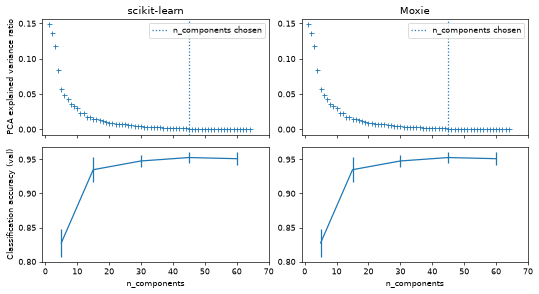

True

In [7]:
def best_per_components(n_comp, means, stds):
    """The polars filter of the example: best mean per n_components (first on ties)."""
    out = []
    for nc in sorted(set(n_comp)):
        idx = [i for i in range(len(n_comp)) if n_comp[i] == nc]
        i = max(idx, key=lambda j: (means[j], -j))
        out.append((nc, means[i], stds[i]))
    return np.array(out)

n_comp = [p["pca__n_components"] for p in res["params"]]
sk_best = best_per_components(n_comp, res["mean_test_score"], res["std_test_score"])
mx_split = np.asarray(mx["split_scores"])
mx_best = best_per_components(n_comp, mx_means, mx_split.std(axis=1))
fig, axes = plt.subplots(2, 2, sharex=True, figsize=(9, 5))
for col, (title, ratio, best, chosen) in enumerate([
        ("scikit-learn", sk_full_pca.explained_variance_ratio_, sk_best, sk_search.best_params_["pca__n_components"]),
        ("Moxie", np.asarray(mx["explained_variance_ratio"]), mx_best, n_comp[int(mx["best_index"][0])])]):
    axes[0, col].plot(np.arange(1, len(ratio) + 1), ratio, "+", linewidth=2)
    axes[0, col].axvline(chosen, linestyle=":", label="n_components chosen")
    axes[0, col].set_title(title); axes[0, col].legend(prop=dict(size=9))
    axes[1, col].errorbar(best[:, 0], best[:, 1], yerr=best[:, 2])
    axes[1, col].set_xlabel("n_components")
axes[0, 0].set_ylabel("PCA explained variance ratio")
axes[1, 0].set_ylabel("Classification accuracy (val)")
plt.xlim(-1, 70); plt.tight_layout(); plt.show()
nb.compare("std_test_score", res["std_test_score"], mx_split.std(axis=1), rtol=0, atol=1e-15,
           reason="computed by NumPy from the exactly matching split scores")

In [8]:
nb.report()
nb.assert_parity()

check,status,sklearn shape,moxie shape,max |diff|,max rel,tolerance,detail,tolerance reason
split test accuracies (20 candidates x 5 folds),PASS,"(20, 5)","(20, 5)",,,exact,0 mismatches,
mean_test_score,PASS,"(20,)","(20,)",0,0,"rtol=0, atol=1e-15",,mean of five identical fold accuracies; NumPy's pairwise mean and a sequential sum may differ in the last bit
best_index_,PASS,"(1,)","(1,)",,,exact,0 mismatches,
best_estimator_.predict(X),PASS,"(1797,)","(1797,)",,,exact,0 mismatches,
PCA().n_components_,PASS,"(1,)","(1,)",,,exact,0 mismatches,
PCA().explained_variance_ratio_,PASS,"(64,)","(64,)",1.67e-16,1,"rtol=1e-09, atol=1e-15",,symmetric eigensolver vs LAPACK on the same covariance; trailing ratios of the 3 constant pixels are ~1e-34 and need the absolute floor
LogisticRegression final step,GAP,,,,,,not implemented in moxie.linear_model (linear_model #8 part 1); SVC() substituted on both sides,
three-step Pipeline,ADAPTED,,,,,,"Moxie Pipeline has two typed steps; nested Pipeline(StandardScaler(), Pipeline(PCA(), SVC())) with typed nested params instead of 'pca__n_components' strings",
"GridSearchCV(pipe, param_grid)",GAP,,,,,,GridSearchCV/cross_val_score over a Pipeline crash the Mojo 1.0 compiler (model_selection #3 part 1); written as the explicit clone/set_params/fit/score loop; fix proposed in patches/cross_family-pipeline-search.patch,
"n_jobs=2, polars cv_results_ table",ADAPTED,,,,,,Moxie is serial; NumPy grouping replaces polars,
